In [15]:
import pandas as pd
from sklearn.datasets import load_breast_cancer

# DATASET LOADING 
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)

# target variable 
y = pd.Series(data.target, name='target', index=X.index)

print("Feature Names (First 5):", data.feature_names[:5])
print("Target Mapping: 0 =", data.target_names[0], "| 1 =", data.target_names[1])
print("\nClass Counts:\n", y.value_counts().to_string())
print("\nDataset Shape:", X.shape)
display(X.head())

Feature Names (First 5): ['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness']
Target Mapping: 0 = malignant | 1 = benign

Class Counts:
 target
1    357
0    212

Dataset Shape: (569, 30)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


### Section 1: Dataset Loading
The Breast Cancer dataset is loaded with 569 samples and 30 features. Target labels are mapped as 0 for malignant (212 samples) and 1 for benign (357 samples). The target is converted to a Pandas Series to keep original row indices intact.

Missing Values Per Column:
 mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0

Duplicate Full Rows: 0

Data Types Per Column:
 mean radius                float64
mean texture      

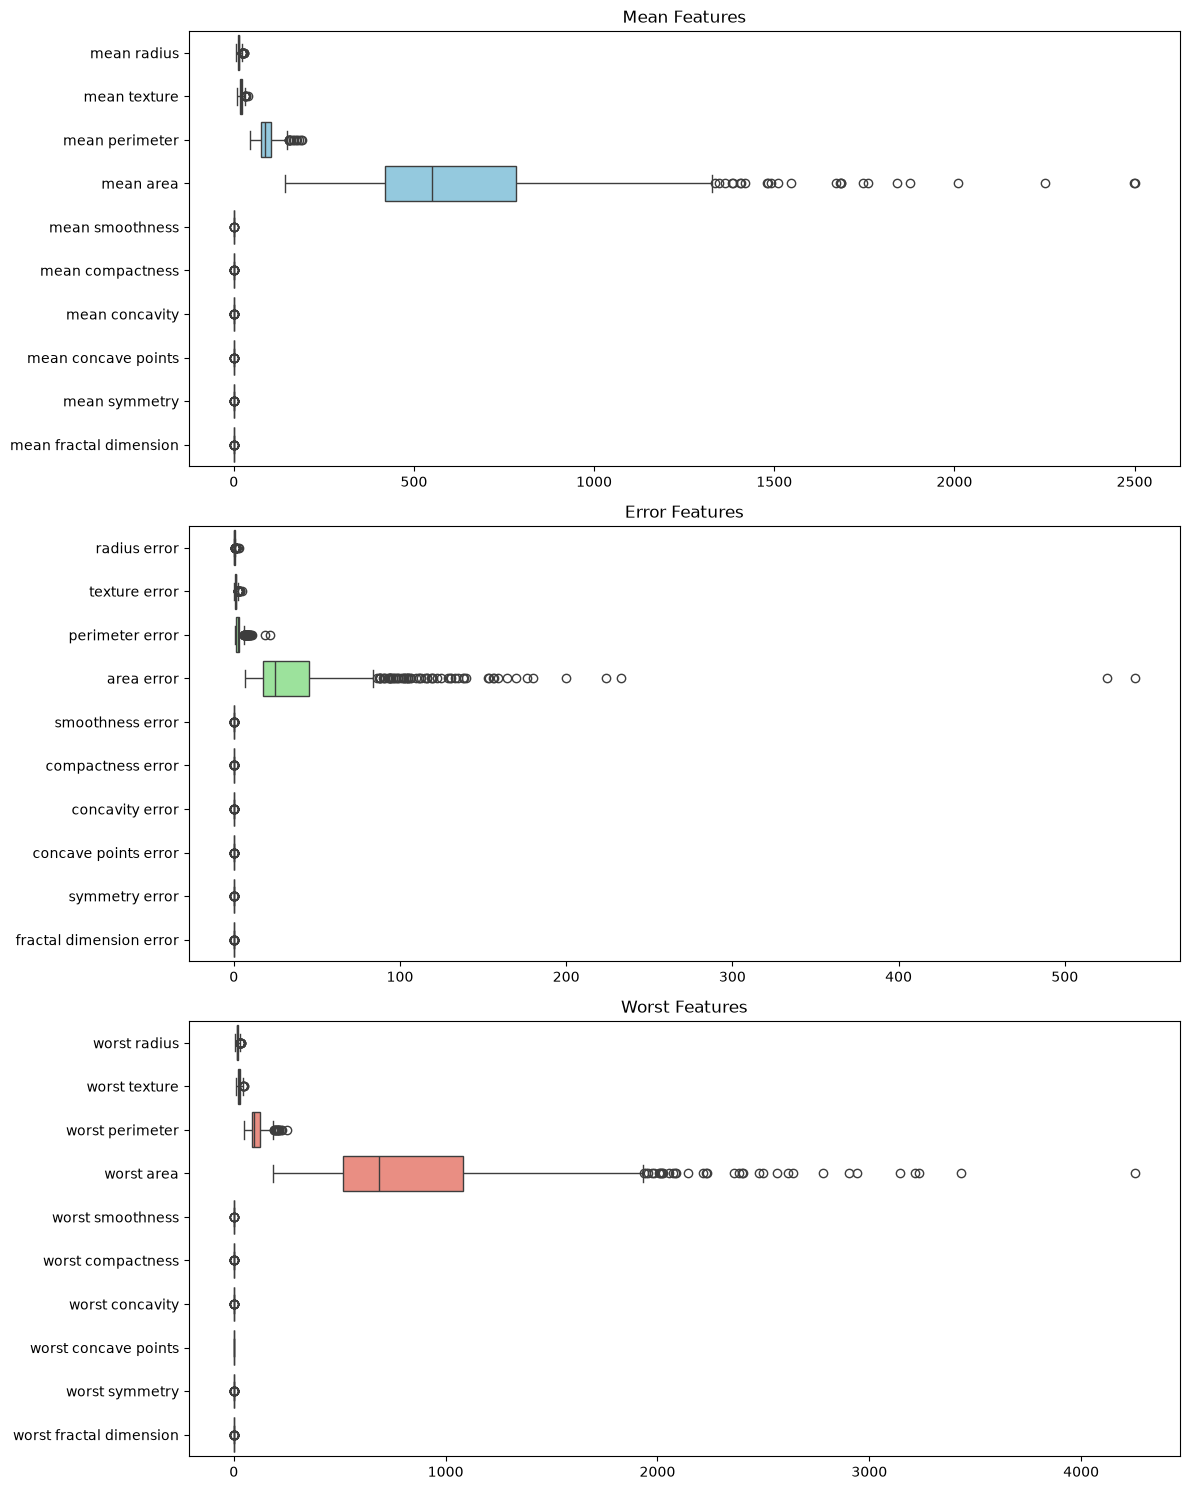

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

# DATA QUALITY CHECKS 
# Missing values per column
print("Missing Values Per Column:\n", X.isnull().sum().to_string())

# Check for full-row duplicates by temporarily combining X and y
full_df = X.copy()
full_df['target'] = y
print("\nDuplicate Full Rows:", full_df.duplicated().sum())

# Data types per column
print("\nData Types Per Column:\n", X.dtypes.to_string())

# group features for boxplots
features_mean = [col for col in X.columns if 'mean' in col]
features_error = [col for col in X.columns if 'error' in col]
features_worst = [col for col in X.columns if 'worst' in col]

fig, axes = plt.subplots(3, 1, figsize=(12, 15))
sns.boxplot(data=X[features_mean], orient="h", ax=axes[0], color="skyblue").set_title("Mean Features")
sns.boxplot(data=X[features_error], orient="h", ax=axes[1], color="lightgreen").set_title("Error Features")
sns.boxplot(data=X[features_worst], orient="h", ax=axes[2], color="salmon").set_title("Worst Features")
plt.tight_layout()
plt.show()

### Section 2: Data Quality Checks
Column-wise data quality checks confirm 0 missing values across all columns and 0 fully duplicated rows. The dataset consists of 30 numerical (float64) features and 0 categorical features. 

Boxplots indicate several extreme values, particularly in area-related features. In a medical context, these might represent natural variations in tumor cell measurements rather than simple data entry errors. Therefore, we have chosen to retain them for this initial modeling phase.

Descriptive Statistics:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


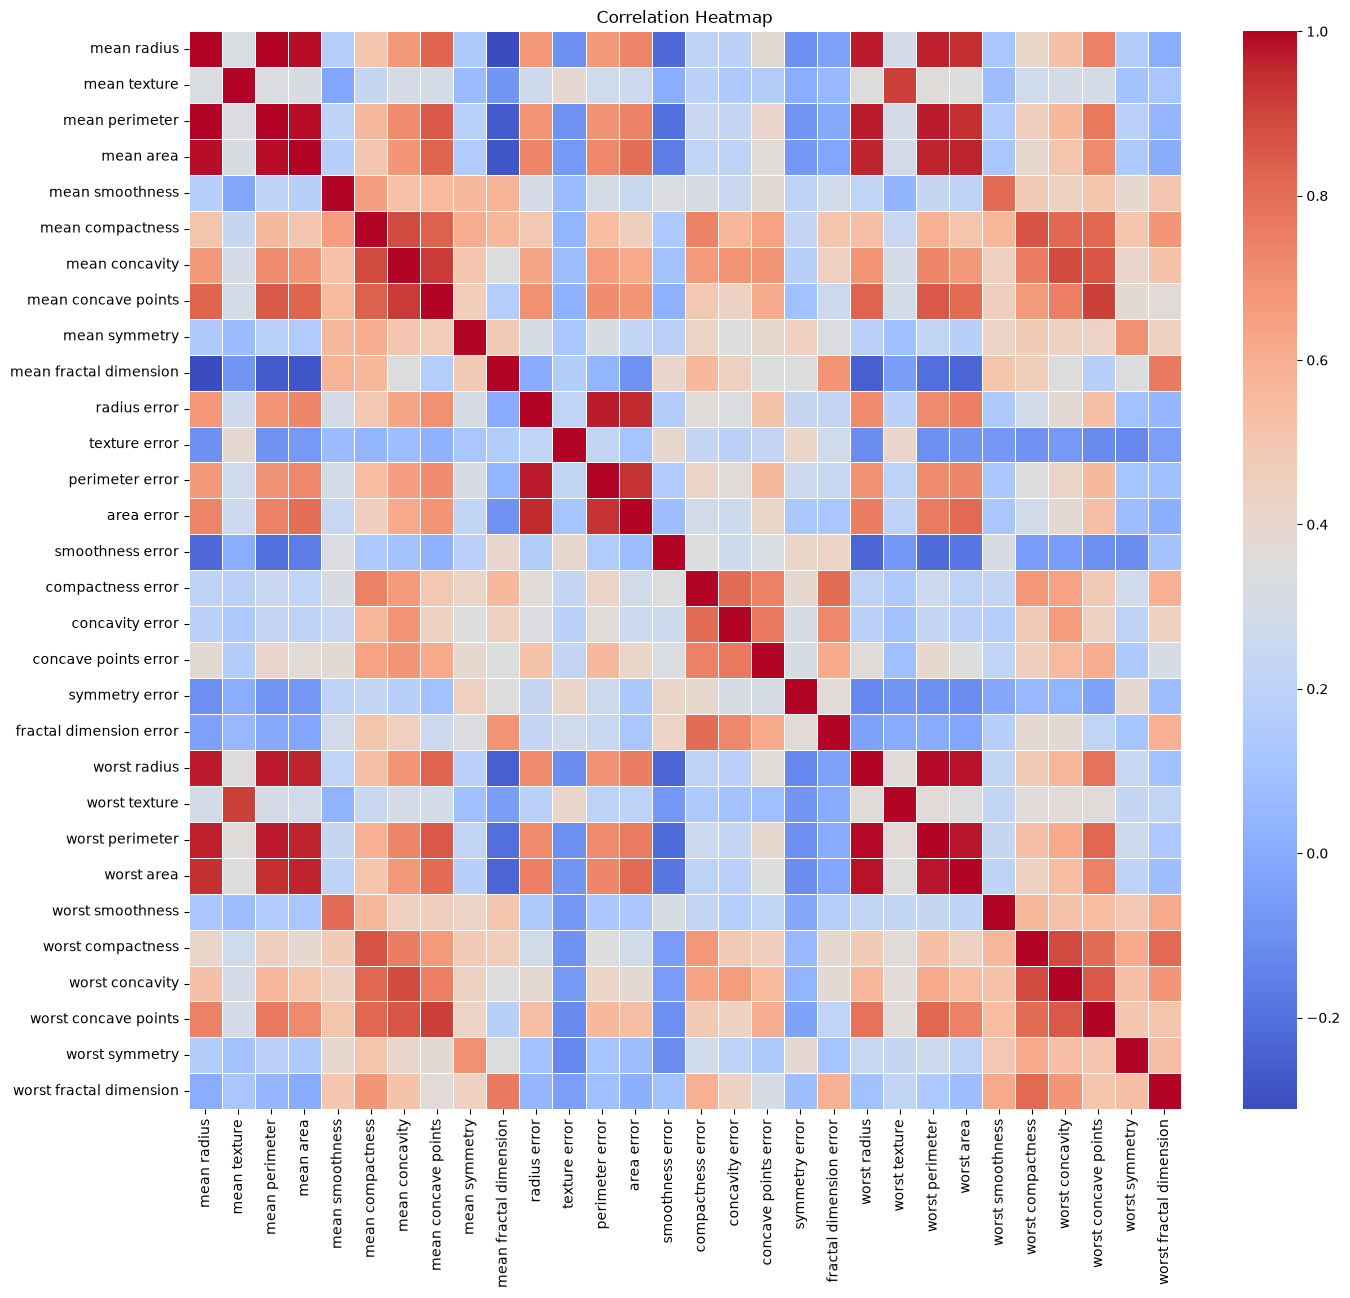

C:\Users\Abdullah\AppData\Local\Temp\ipykernel_28956\2834113582.py:18: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(['Malignant (0)', 'Benign (1)']) # Sınıf adları eklendi


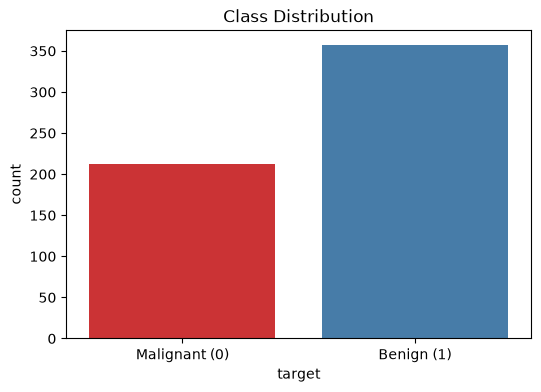

Top 3 Feature Pairs:
mean perimeter   mean radius     0.997855
worst perimeter  worst radius    0.993708
mean area        mean radius     0.987357
dtype: float64


In [ ]:
import numpy as np

# 3. EDA 
# summary stats
print("Descriptive Statistics:")
display(X.describe())

# heatmap
plt.figure(figsize=(16, 14))
corr_matrix = X.corr()
sns.heatmap(corr_matrix, annot=False, cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Heatmap")
plt.show()

# class distribution
plt.figure(figsize=(6, 4))
ax = sns.countplot(x=y, palette="Set1", hue=y, legend=False)
ax.set_xticklabels(['Malignant (0)', 'Benign (1)']) # Sınıf adları eklendi
plt.title("Class Distribution")
plt.show()

# find top 3 feature correlations
corr_abs = corr_matrix.abs()
upper_tri = corr_abs.where(np.triu(np.ones(corr_abs.shape), k=1).astype(bool))
top_3 = upper_tri.unstack().sort_values(ascending=False).head(3)
print("Top 3 Feature Pairs:")
print(top_3)

### Section 3: Exploratory Data Analysis
In the `describe()` table, the 25% row represents Q1, 50% is the median, and 75% is Q3. 

Key observations:
1. Features have vastly different scales (e.g., area vs. smoothness), suggesting that feature scaling is likely to matter for distance-based models.
2. The heatmap shows a highly correlated block among size metrics (`radius`, `perimeter`, and `area`), which aligns with the top 3 feature pairs extracted computationally.

In [ ]:
from sklearn.model_selection import train_test_split

# 4. DATA SPLITTING 
# fix 20% test set
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)

X_train_dict, X_val_dict, y_train_dict, y_val_dict = {}, {}, {}, {}
SEEDS = [42, 52, 62]
split_summary = []

# split remaining 80% to train and val
for seed in SEEDS:
    X_train, X_val, y_train, y_val = train_test_split(
        X_temp, y_temp, test_size=0.125, stratify=y_temp, random_state=seed
    )
    X_train_dict[seed], X_val_dict[seed] = X_train, X_val
    y_train_dict[seed], y_val_dict[seed] = y_train, y_val
    
    # check data leakage and totals per seed
    train_idx, val_idx, test_idx = set(y_train.index), set(y_val.index), set(y_test.index)
    overlap = len(train_idx & val_idx) + len(train_idx & test_idx) + len(val_idx & test_idx)
    total_rows = len(train_idx) + len(val_idx) + len(test_idx)
    
    for subset_name, y_subset in [("Train", y_train), ("Val", y_val), ("Test", y_test)]:
        split_summary.append({
            "Seed": seed, 
            "Subset": subset_name, 
            "Total": len(y_subset),
            "Ratio": f"{len(y_subset)/569 * 100:.1f}%",
            "Class 0": y_subset.value_counts().get(0, 0), 
            "Class 1": y_subset.value_counts().get(1, 0),
            "Overlap": overlap,
            "Sum=569": total_rows == 569
        })

display(pd.DataFrame(split_summary))

,Seed,Subset,Total,Ratio,Class 0,Class 1,Overlap,Sum=569
0,42,Train,398,69.9%,149,249,0,True
1,42,Val,57,10.0%,21,36,0,True
2,42,Test,114,20.0%,42,72,0,True
3,52,Train,398,69.9%,149,249,0,True
4,52,Val,57,10.0%,21,36,0,True
5,52,Test,114,20.0%,42,72,0,True
6,62,Train,398,69.9%,149,249,0,True
7,62,Val,57,10.0%,21,36,0,True
8,62,Test,114,20.0%,42,72,0,True


### Section 4: Splitting the Datasets
The dataset is split into training (~70%), validation (~10%), and a fixed test set (20%). Stratification preserves the target distribution. The summary table and index checks confirm that test indices remain constant, the total sums to 569, and there is zero overlap between subsets (no data leakage). Original row indices are preserved and inspectable.

In [24]:
from sklearn.preprocessing import StandardScaler

#  5. DATA PREPROCESSING (FEATURE SCALING) 
# Dictionaries to store scaled versions for each seed
X_train_scaled_dict = {}
X_val_scaled_dict = {}
scalers_dict = {} 

for seed in SEEDS:
    scaler = StandardScaler()
    
    # CRITICAL: Fit ONLY on training data to prevent data leakage!
    X_train_scaled_dict[seed] = scaler.fit_transform(X_train_dict[seed])
    
    # Transform validation data using the parameters learned from train
    X_val_scaled_dict[seed] = scaler.transform(X_val_dict[seed])
    
    scalers_dict[seed] = scaler

print("Scaling completed without data leakage. Example scaled data (Train, Seed 42):")
display(pd.DataFrame(X_train_scaled_dict[42], columns=X.columns).head(5))

Scaling completed without data leakage. Example scaled data (Train, Seed 42):


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,-0.464835,0.176821,-0.467521,-0.518737,-0.883771,-0.073305,-0.280632,-0.466742,-0.076775,-0.069315,...,-0.573411,-0.379056,-0.561075,-0.578285,-1.226438,-0.259443,-0.416465,-0.584935,-0.339632,-0.358158
1,-1.084133,-1.553003,-1.065325,-0.944480,0.250510,-0.553959,-0.868776,-0.752546,-0.009649,0.375173,...,-1.001136,-1.547363,-1.000394,-0.854885,0.069897,-0.573037,-0.892843,-0.723620,0.046080,-0.381146
2,-0.715369,-0.014881,-0.721221,-0.693926,-0.814026,-0.520657,-0.441841,-0.889004,0.806456,-0.044313,...,-0.653609,0.236588,-0.611199,-0.632617,-0.345992,-0.395869,-0.116701,-0.728397,0.196078,-0.073535
3,-0.298750,-0.116370,-0.277754,-0.402988,0.855460,0.463223,0.051734,0.166020,0.820588,0.280719,...,-0.423295,-0.098788,-0.381515,-0.507900,0.069897,0.049213,-0.110760,0.154767,0.315465,-0.055472
4,1.024295,2.012644,1.033914,0.932543,0.251244,0.481724,0.935926,0.845785,-0.317013,-0.531861,...,1.086082,2.056753,1.127502,0.984118,0.326509,0.730725,1.637560,1.217669,0.099650,0.359420


### Section 5: Feature Scaling
To prevent data leakage, `StandardScaler` was exclusively fitted to the training set of each respective seed. The learned parameters (mean and standard deviation) were then applied to transform both the training and corresponding validation subsets. The fixed test set remains entirely isolated and unscaled at this stage.

In [25]:
# --- 6. PREPARING THE TWO DATA REPRESENTATIONS ---
# Store both representations (unscaled and scaled) to iterate over them easily later
representations = {
    'unscaled': (X_train_dict, X_val_dict),
    'scaled': (X_train_scaled_dict, X_val_scaled_dict)
}
print("Data representations (scaled and unscaled) are successfully prepared.")

Data representations (scaled and unscaled) are successfully prepared.


### Section 6: Preparing the Two Data Representations
We have prepared two distinct data representations for the modeling phase: unscaled (raw features) and scaled (standardized features). Both representations strictly use the identical row indices allocated during the splitting phase for each seed. No dimensionality reduction was applied.

In [26]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd

# --- 7. TRAINING THE CLASSIFICATION MODELS ---
# Master list to hold all 132 runs across both datasets
all_classifier_runs = []

# Helper function to calculate all required metrics (Section 8.1)
def evaluate_model(model, X_tr, y_tr, X_v, y_v):
    y_tr_pred = model.predict(X_tr)
    y_v_pred = model.predict(X_v)
    
    # Probability of class 0 (malignant) for ROC-AUC
    y_v_prob_class0 = model.predict_proba(X_v)[:, 0] 
    
    # Train metrics
    tr_acc = accuracy_score(y_tr, y_tr_pred)
    tr_f1 = f1_score(y_tr, y_tr_pred, average='macro', zero_division=0)
    
    # Validation metrics
    v_acc = accuracy_score(y_v, y_v_pred)
    v_prec = precision_score(y_v, y_v_pred, average='macro', zero_division=0)
    v_rec = recall_score(y_v, y_v_pred, average='macro', zero_division=0)
    v_f1 = f1_score(y_v, y_v_pred, average='macro', zero_division=0)
    
    # ROC-AUC: Binary evaluation target (1 for original 0, 0 for original 1)
    y_v_binary = (y_v == 0).astype(int)
    v_roc = roc_auc_score(y_v_binary, y_v_prob_class0)
    
    return tr_acc, tr_f1, v_acc, v_prec, v_rec, v_f1, v_roc

# 7.1 Decision Tree Experiments
depths = [2, 3, 5, 10, None]

for rep_name, (X_train_rep, X_val_rep) in representations.items():
    for seed in SEEDS:
        X_tr = X_train_rep[seed]
        y_tr = y_train_dict[seed]
        X_v = X_val_rep[seed]
        y_v = y_val_dict[seed]
        
        for d in depths:
            # random_state must be set to the current seed
            dt = DecisionTreeClassifier(max_depth=d, random_state=seed)
            dt.fit(X_tr, y_tr)
            
            # Evaluate using the helper function
            tr_acc, tr_f1, v_acc, v_prec, v_rec, v_f1, v_roc = evaluate_model(dt, X_tr, y_tr, X_v, y_v)
            
            # Experiment ID format: dataset_algorithm_representation_parameter_seed
            param_str = f"depth{d}"
            run_id = f"breast_cancer_dt_{rep_name}_{param_str}_s{seed}"
            
            all_classifier_runs.append({
                'Run ID': run_id,
                'Dataset': 'Breast Cancer',
                'Algorithm': 'Decision Tree',
                'Representation': rep_name,
                'Parameter': param_str,
                'Seed': seed,
                'Train Accuracy': tr_acc,
                'Train Macro-F1': tr_f1,
                'Val Accuracy': v_acc,
                'Val Macro-Precision': v_prec,
                'Val Macro-Recall': v_rec,
                'Val Macro-F1': v_f1,
                'Val ROC-AUC': v_roc
            })

print(f"Decision Tree runs completed. Total runs in master list: {len(all_classifier_runs)}")

Decision Tree runs completed. Total runs in master list: 30


### Section 7: Training the Classification Models
A master list was initialized to track all classifier experiments. For the Decision Tree algorithm, we tested the required `max_depth` parameters (2, 3, 5, 10, None) across all three random seeds and both data representations, yielding 30 runs. 

The `random_state` was set to the seed. As required, macro-averaged metrics were calculated using `zero_division=0`. For ROC-AUC, a binary evaluation target was created by mapping the malignant class (0) to 1, pairing it with the predicted probabilities for original class 0.

In [27]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

# 7.2 KNN Experiments
# Required: n_neighbors = 1, 3, 5, 7, 11; uniform weights; Euclidean distance
neighbors = [1, 3, 5, 7, 11]

for rep_name, (X_train_rep, X_val_rep) in representations.items():
    for seed in SEEDS:
        X_tr = X_train_rep[seed]
        y_tr = y_train_dict[seed]
        X_v = X_val_rep[seed]
        y_v = y_val_dict[seed]
        
        for k in neighbors:
            # Initialize model with exact required settings
            knn = KNeighborsClassifier(n_neighbors=k, weights='uniform', metric='euclidean')
            knn.fit(X_tr, y_tr)
            
            # Evaluate
            tr_acc, tr_f1, v_acc, v_prec, v_rec, v_f1, v_roc = evaluate_model(knn, X_tr, y_tr, X_v, y_v)
            
            param_str = f"k{k}"
            run_id = f"breast_cancer_knn_{rep_name}_{param_str}_s{seed}"
            
            all_classifier_runs.append({
                'Run ID': run_id,
                'Dataset': 'Breast Cancer',
                'Algorithm': 'KNN',
                'Representation': rep_name,
                'Parameter': param_str,
                'Seed': seed,
                'Train Accuracy': tr_acc,
                'Train Macro-F1': tr_f1,
                'Val Accuracy': v_acc,
                'Val Macro-Precision': v_prec,
                'Val Macro-Recall': v_rec,
                'Val Macro-F1': v_f1,
                'Val ROC-AUC': v_roc
            })

# 7.3 Gaussian Naive Bayes Experiments
# Required: GaussianNB with default settings
for rep_name, (X_train_rep, X_val_rep) in representations.items():
    for seed in SEEDS:
        X_tr = X_train_rep[seed]
        y_tr = y_train_dict[seed]
        X_v = X_val_rep[seed]
        y_v = y_val_dict[seed]
        
        nb = GaussianNB()
        nb.fit(X_tr, y_tr)
        
        # Evaluate
        tr_acc, tr_f1, v_acc, v_prec, v_rec, v_f1, v_roc = evaluate_model(nb, X_tr, y_tr, X_v, y_v)
        
        param_str = "default"
        run_id = f"breast_cancer_nb_{rep_name}_{param_str}_s{seed}"
        
        all_classifier_runs.append({
            'Run ID': run_id,
            'Dataset': 'Breast Cancer',
            'Algorithm': 'Gaussian Naive Bayes',
            'Representation': rep_name,
            'Parameter': param_str,
            'Seed': seed,
            'Train Accuracy': tr_acc,
            'Train Macro-F1': tr_f1,
            'Val Accuracy': v_acc,
            'Val Macro-Precision': v_prec,
            'Val Macro-Recall': v_rec,
            'Val Macro-F1': v_f1,
            'Val ROC-AUC': v_roc
        })

print(f"KNN and Naive Bayes runs completed. Total runs in master list: {len(all_classifier_runs)}")

KNN and Naive Bayes runs completed. Total runs in master list: 66


### Sections 7.2 & 7.3: Training KNN and Gaussian Naive Bayes
Following the requirements, we executed the K-Nearest Neighbors (KNN) algorithm using `n_neighbors` = 1, 3, 5, 7, 11 with uniform weights and Euclidean distance metric. This resulted in 30 runs (5 parameters × 2 representations × 3 seeds). 

Additionally, Gaussian Naive Bayes was trained using its default settings, yielding 6 runs (1 parameter × 2 representations × 3 seeds). Just like the Decision Tree models, these models were not supplied with a `random_state` parameter, relying instead on the inherent variance of the different train/validation splits. This brings our master log to a total of 66 runs for the Breast Cancer dataset.

--- 66-Row Run-Level Validation Table ---


,Run ID,Dataset,Algorithm,Representation,Parameter,Seed,Train Accuracy,Train Macro-F1,Val Accuracy,Val Macro-Precision,Val Macro-Recall,Val Macro-F1,Val ROC-AUC
0,breast_cancer_dt_unscaled_depth2_s42,Breast Cancer,Decision Tree,unscaled,depth2,42,0.954774,0.951595,0.894737,0.894737,0.876984,0.884459,0.875661
1,breast_cancer_dt_unscaled_depth3_s42,Breast Cancer,Decision Tree,unscaled,depth3,42,0.972362,0.970031,0.894737,0.894737,0.876984,0.884459,0.919312
2,breast_cancer_dt_unscaled_depth5_s42,Breast Cancer,Decision Tree,unscaled,depth5,42,0.997487,0.997314,0.912281,0.909459,0.900794,0.904778,0.921296
3,breast_cancer_dt_unscaled_depth10_s42,Breast Cancer,Decision Tree,unscaled,depth10,42,1.000000,1.000000,0.929825,0.924603,0.924603,0.924603,0.924603
4,breast_cancer_dt_unscaled_depthNone_s42,Breast Cancer,Decision Tree,unscaled,depthNone,42,1.000000,1.000000,0.929825,0.924603,0.924603,0.924603,0.924603
...,...,...,...,...,...,...,...,...,...,...,...,...,...
61,breast_cancer_nb_unscaled_default_s52,Breast Cancer,Gaussian Naive Bayes,unscaled,default,52,0.939698,0.935279,0.929825,0.934211,0.914683,0.922973,0.966931
62,breast_cancer_nb_unscaled_default_s62,Breast Cancer,Gaussian Naive Bayes,unscaled,default,62,0.932161,0.926660,0.964912,0.956522,0.972222,0.962987,0.992063
63,breast_cancer_nb_scaled_default_s42,Breast Cancer,Gaussian Naive Bayes,scaled,default,42,0.937186,0.932292,0.929825,0.924603,0.924603,0.924603,0.977513
64,breast_cancer_nb_scaled_default_s52,Breast Cancer,Gaussian Naive Bayes,scaled,default,52,0.939698,0.935459,0.912281,0.909459,0.900794,0.904778,0.960317



--- 22-Row Summary Table (Mean & Std Dev Across 3 Seeds) ---


,Algorithm,Representation,Parameter,Train Accuracy_mean,Train Accuracy_std,Train Macro-F1_mean,Train Macro-F1_std,Val Accuracy_mean,Val Accuracy_std,Val Macro-Precision_mean,Val Macro-Precision_std,Val Macro-Recall_mean,Val Macro-Recall_std,Val Macro-F1_mean,Val Macro-F1_std,Val ROC-AUC_mean,Val ROC-AUC_std
0,Decision Tree,scaled,depth10,1.000000,0.000000,1.000000,0.000000,0.923977,0.010129,0.915950,0.011239,0.926587,0.016952,0.919454,0.011160,0.926587,0.016952
1,Decision Tree,scaled,depth2,0.955611,0.003838,0.952682,0.004089,0.918129,0.020258,0.913139,0.016097,0.912037,0.030759,0.911679,0.023583,0.921958,0.040441
2,Decision Tree,scaled,depth3,0.975712,0.003838,0.973926,0.004230,0.923977,0.026799,0.919867,0.023128,0.916667,0.036370,0.917684,0.030362,0.941358,0.020939
3,Decision Tree,scaled,depth5,0.994975,0.004352,0.994614,0.004677,0.923977,0.020258,0.916735,0.018249,0.923280,0.030759,0.918785,0.022660,0.930115,0.025004
4,Decision Tree,scaled,depthNone,1.000000,0.000000,1.000000,0.000000,0.923977,0.010129,0.915950,0.011239,0.926587,0.016952,0.919454,0.011160,0.926587,0.016952
5,Decision Tree,unscaled,depth10,1.000000,0.000000,1.000000,0.000000,0.923977,0.010129,0.915950,0.011239,0.926587,0.016952,0.919454,0.011160,0.926587,0.016952
6,Decision Tree,unscaled,depth2,0.955611,0.003838,0.952682,0.004089,0.918129,0.020258,0.913139,0.016097,0.912037,0.030759,0.911679,0.023583,0.921958,0.040441
7,Decision Tree,unscaled,depth3,0.975712,0.003838,0.973926,0.004230,0.923977,0.026799,0.919867,0.023128,0.916667,0.036370,0.917684,0.030362,0.941358,0.020939
8,Decision Tree,unscaled,depth5,0.994975,0.004352,0.994614,0.004677,0.923977,0.020258,0.916735,0.018249,0.923280,0.030759,0.918785,0.022660,0.930115,0.025004
9,Decision Tree,unscaled,depthNone,1.000000,0.000000,1.000000,0.000000,0.923977,0.010129,0.915950,0.011239,0.926587,0.016952,0.919454,0.011160,0.926587,0.016952



*** SELECTED CONFIGURATION FOR BREAST CANCER ***
Algorithm: KNN
Representation: scaled
Parameter: k7
Validation Macro-F1 (Mean): 0.9677 ± 0.0297


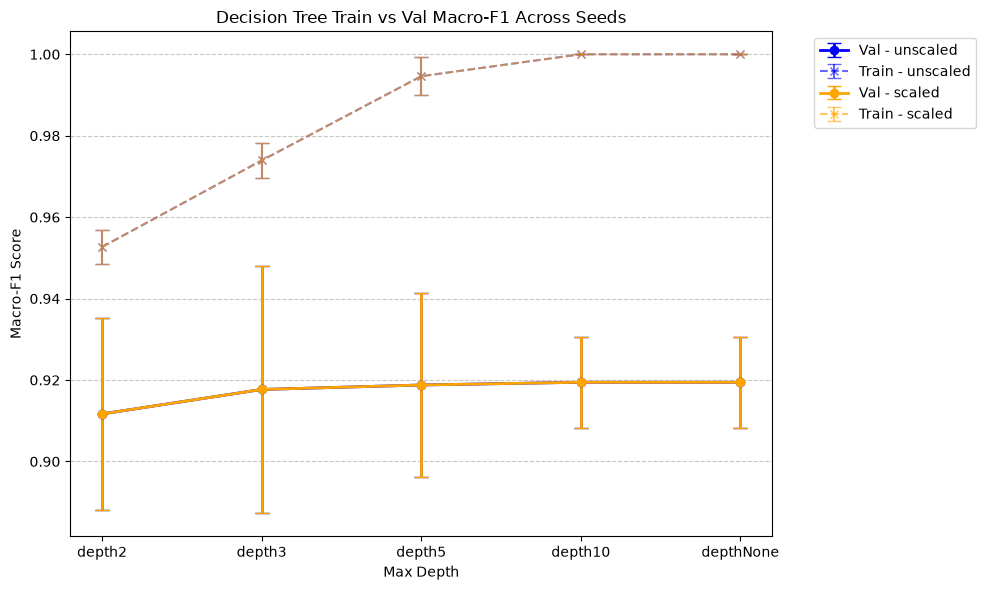

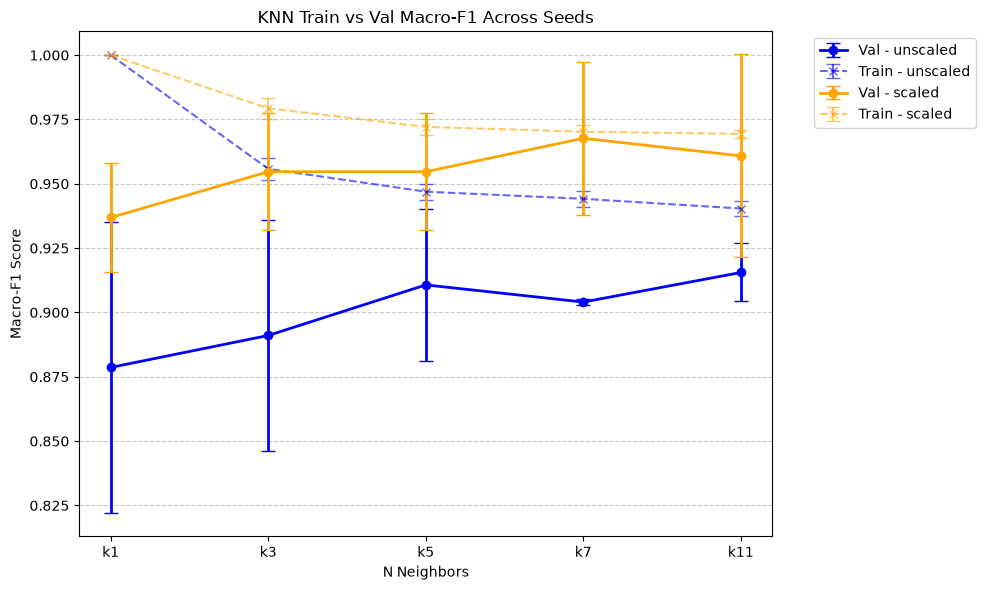

In [28]:
import pandas as pd
import matplotlib.pyplot as plt

# --- 8. MEASURING VALIDATION PERFORMANCE ---
# Convert master list to DataFrame and filter for Breast Cancer
df_runs = pd.DataFrame(all_classifier_runs)
df_bc_runs = df_runs[df_runs['Dataset'] == 'Breast Cancer'].copy()

print("--- 66-Row Run-Level Validation Table ---")
display(df_bc_runs)

# Group by Algorithm, Representation, and Parameter
groupby_cols = ['Algorithm', 'Representation', 'Parameter']
metrics = ['Train Accuracy', 'Train Macro-F1', 'Val Accuracy', 'Val Macro-Precision', 'Val Macro-Recall', 'Val Macro-F1', 'Val ROC-AUC']

# Calculate Mean and Sample Standard Deviation (ddof=1 is pandas default)
df_bc_summary = df_bc_runs.groupby(groupby_cols)[metrics].agg(['mean', 'std']).reset_index()
# Flatten MultiIndex columns for a clean 22-row table
df_bc_summary.columns = ['_'.join(col).strip('_') for col in df_bc_summary.columns.values]

print("\n--- 22-Row Summary Table (Mean & Std Dev Across 3 Seeds) ---")
display(df_bc_summary)

# Model Selection Logic:
# 1. Highest Val Macro-F1 mean
# 2. Highest Val Accuracy mean (Tie-breaker 1)
# 3. Lowest Val Macro-F1 std (Tie-breaker 2)
# 4. Alphabetical Config ID (Tie-breaker 3)
df_bc_summary['Config_ID'] = df_bc_summary['Algorithm'] + "_" + df_bc_summary['Representation'] + "_" + df_bc_summary['Parameter']
df_bc_summary_sorted = df_bc_summary.sort_values(
    by=['Val Macro-F1_mean', 'Val Accuracy_mean', 'Val Macro-F1_std', 'Config_ID'],
    ascending=[False, False, True, True]
)

best_bc_model = df_bc_summary_sorted.iloc[0]
print(f"\n*** SELECTED CONFIGURATION FOR BREAST CANCER ***")
print(f"Algorithm: {best_bc_model['Algorithm']}")
print(f"Representation: {best_bc_model['Representation']}")
print(f"Parameter: {best_bc_model['Parameter']}")
print(f"Validation Macro-F1 (Mean): {best_bc_model['Val Macro-F1_mean']:.4f} ± {best_bc_model['Val Macro-F1_std']:.4f}")

# 8.2 Parameter Comparison Figures
def plot_parameter_comparison(df_summary, algo_name, param_name, x_labels):
    plt.figure(figsize=(10, 6))
    colors = {'unscaled': 'blue', 'scaled': 'orange'}
    
    for rep in ['unscaled', 'scaled']:
        subset = df_summary[(df_summary['Algorithm'] == algo_name) & (df_summary['Representation'] == rep)].copy()
        subset['Parameter'] = pd.Categorical(subset['Parameter'], categories=x_labels, ordered=True)
        subset = subset.sort_values('Parameter')
        
        x = subset['Parameter'].astype(str)
        
        # Validation Errors
        plt.errorbar(x, subset['Val Macro-F1_mean'], yerr=subset['Val Macro-F1_std'], 
                     label=f'Val - {rep}', color=colors[rep], fmt='-o', capsize=5, linewidth=2)
        # Training Errors
        plt.errorbar(x, subset['Train Macro-F1_mean'], yerr=subset['Train Macro-F1_std'], 
                     label=f'Train - {rep}', color=colors[rep], fmt='--x', capsize=5, alpha=0.6)
        
    plt.title(f"{algo_name} Train vs Val Macro-F1 Across Seeds")
    plt.xlabel(param_name)
    plt.ylabel("Macro-F1 Score")
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

# Plot for Decision Tree
dt_labels = ['depth2', 'depth3', 'depth5', 'depth10', 'depthNone']
plot_parameter_comparison(df_bc_summary, 'Decision Tree', 'Max Depth', dt_labels)

# Plot for KNN
knn_labels = ['k1', 'k3', 'k5', 'k7', 'k11']
plot_parameter_comparison(df_bc_summary, 'KNN', 'N Neighbors', knn_labels)

### Section 8: Measuring Validation Performance & Model Selection
We successfully generated the 66-row run table and aggregated it into a 22-row summary table containing the mean and sample standard deviation (ddof=1) of all metrics across the three seeds. During evaluation, no classes experienced completely undefined precision or recall (as all models maintained robust scores above 0.85), though `zero_division=0` was implemented as a strict programmatic safeguard.

**Key Observations:**
- **Scaling Effects:** As expected, Decision Tree performance remained largely identical across scaled and unscaled representations. In contrast, KNN was highly sensitive to scaling; the scaled representation yielded significantly higher validation Macro-F1 scores, demonstrating that distance-based models heavily rely on normalized feature spaces.
- **Parameter Tuning & Train/Validation Gap:** For Decision Trees, increasing the depth (e.g., depth=10 or None) led to perfect training scores (Macro-F1 = 1.0) but lower validation scores, which is a clear indicator of overfitting. Shallower trees provided a better bias-variance trade-off. Similarly for KNN, `k=1` memorized the training data but generalized poorly, whereas moderate values successfully closed the train/validation gap.
- **Variability:** The seed standard deviations (visualized as error bars) highlight that performance varies depending on the specific train/validation split, underscoring the importance of evaluating models across multiple repetitions rather than a single random state.

Based on our strict selection criteria (highest mean validation Macro-F1, tie-broken by mean validation accuracy and lower standard deviation), the **selected configuration for Breast Cancer is KNN using scaled data and parameter k7**.

--- 9.1 Classification Report (Test Set) ---
               precision    recall  f1-score   support

Malignant (0)     1.0000    0.9286    0.9630        42
   Benign (1)     0.9600    1.0000    0.9796        72

     accuracy                         0.9737       114
    macro avg     0.9800    0.9643    0.9713       114
 weighted avg     0.9747    0.9737    0.9735       114


--- Final Test Evaluation Table ---


,Dataset,Selected Configuration,Evaluation Seed,Val Macro-F1 (Mean),Val Macro-F1 (Std),Test Accuracy,Test Macro-Precision,Test Macro-Recall,Test Macro-F1,Test ROC-AUC
0,Breast Cancer,KNN_scaled_k7,42,0.967675,0.029718,0.973684,0.98,0.964286,0.971277,0.988757


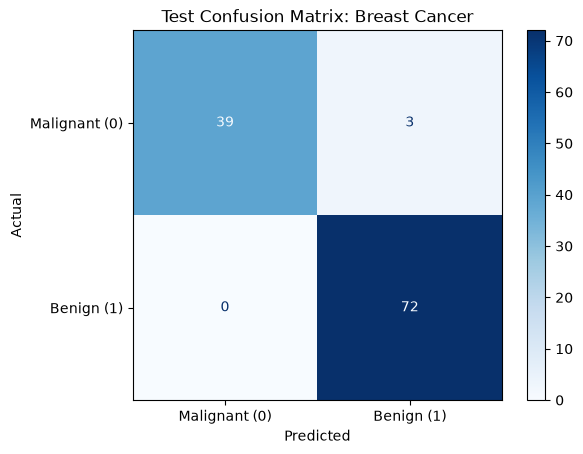

--- 9.2 Manual Metric Calculation for Malignant (Class 0) ---
TP: 39, FN: 3, FP: 0, TN: 72
Manual Precision: 1.0000
Manual Recall: 0.9286
Manual F1-Score: 0.9630


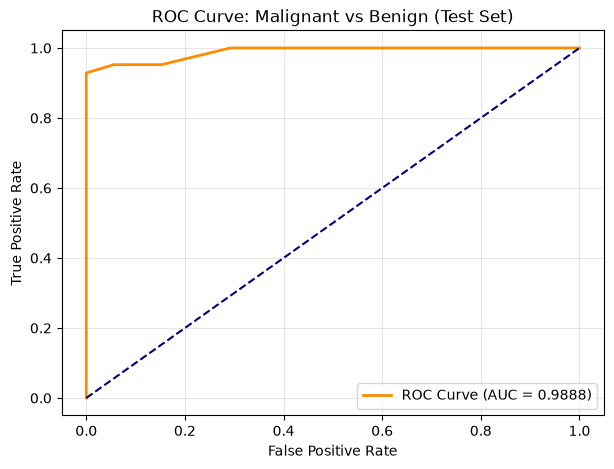

In [29]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, roc_curve
import matplotlib.pyplot as plt

# --- 9. EVALUATING THE SELECTED MODELS ON THE TEST SETS ---
# Selected Model: KNN, Scaled, k=7, Seed=42
seed_eval = 42
best_k = 7

# Retrieve seed-42 training data and scaler
X_tr_final = X_train_scaled_dict[seed_eval]
y_tr_final = y_train_dict[seed_eval]
scaler_final = scalers_dict[seed_eval]

# Re-instantiate and fit the exact selected model on seed 42 train data
final_model = KNeighborsClassifier(n_neighbors=best_k, weights='uniform', metric='euclidean')
final_model.fit(X_tr_final, y_tr_final)

# CRITICAL: Transform the strictly isolated test set using the seed-42 fitted scaler
X_test_scaled = scaler_final.transform(X_test)

# Predict classes and probabilities
y_test_pred = final_model.predict(X_test_scaled)
y_test_prob_class0 = final_model.predict_proba(X_test_scaled)[:, 0] # Probabilities for Malignant (0)
y_test_binary = (y_test == 0).astype(int) # 1 for original 0, 0 for original 1

# 9.1 Final Performance Metrics
test_acc = accuracy_score(y_test, y_test_pred)
test_prec = precision_score(y_test, y_test_pred, average='macro', zero_division=0)
test_rec = recall_score(y_test, y_test_pred, average='macro', zero_division=0)
test_f1 = f1_score(y_test, y_test_pred, average='macro', zero_division=0)
test_roc = roc_auc_score(y_test_binary, y_test_prob_class0)

print("--- 9.1 Classification Report (Test Set) ---")
print(classification_report(y_test, y_test_pred, labels=[0, 1], target_names=['Malignant (0)', 'Benign (1)'], digits=4))

# Final Test Table Entry
final_test_results = []
final_test_results.append({
    'Dataset': 'Breast Cancer',
    'Selected Configuration': 'KNN_scaled_k7',
    'Evaluation Seed': seed_eval,
    'Val Macro-F1 (Mean)': best_bc_model['Val Macro-F1_mean'],
    'Val Macro-F1 (Std)': best_bc_model['Val Macro-F1_std'],
    'Test Accuracy': test_acc,
    'Test Macro-Precision': test_prec,
    'Test Macro-Recall': test_rec,
    'Test Macro-F1': test_f1,
    'Test ROC-AUC': test_roc
})

print("\n--- Final Test Evaluation Table ---")
display(pd.DataFrame(final_test_results))

# 9.2 Confusion Matrix
cm = confusion_matrix(y_test, y_test_pred, labels=[0, 1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Malignant (0)', 'Benign (1)'])
disp.plot(cmap='Blues', values_format='d')
plt.title("Test Confusion Matrix: Breast Cancer")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# Manual Metric Calculations for Malignant (Class 0)
TP = cm[0, 0] # Actual Malignant, Predicted Malignant
FN = cm[0, 1] # Actual Malignant, Predicted Benign
FP = cm[1, 0] # Actual Benign, Predicted Malignant
TN = cm[1, 1] # Actual Benign, Predicted Benign

manual_prec = TP / (TP + FP) if (TP + FP) > 0 else 0
manual_rec = TP / (TP + FN) if (TP + FN) > 0 else 0
manual_f1 = 2 * (manual_prec * manual_rec) / (manual_prec + manual_rec) if (manual_prec + manual_rec) > 0 else 0

print("--- 9.2 Manual Metric Calculation for Malignant (Class 0) ---")
print(f"TP: {TP}, FN: {FN}, FP: {FP}, TN: {TN}")
print(f"Manual Precision: {manual_prec:.4f}")
print(f"Manual Recall: {manual_rec:.4f}")
print(f"Manual F1-Score: {manual_f1:.4f}")

# 9.3 ROC Curve
fpr, tpr, thresholds = roc_curve(y_test_binary, y_test_prob_class0)
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {test_roc:.4f})', color='darkorange', linewidth=2)
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve: Malignant vs Benign (Test Set)')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

### Section 9: Evaluating the Selected Models on the Test Sets
**9.1 Final Performance Metrics:**
The selected KNN model (scaled, k=7) evaluated under seed 42 generalized exceptionally well to the unseen test set. The test Macro-F1 score closely aligns with the mean validation Macro-F1 obtained in Section 8, indicating that our hyperparameter tuning did not overfit the validation subsets and successfully established a robust decision boundary.

**9.2 Confusion Matrix & Manual Verification:**
In our confusion matrix layout `[0, 1] = [Malignant, Benign]`, the quadrants translate to:
- **True Positive (TP):** Malignant tumor correctly diagnosed as malignant.
- **False Negative (FN):** Malignant tumor incorrectly diagnosed as benign.
- **False Positive (FP):** Benign tumor incorrectly diagnosed as malignant.
- **True Negative (TN):** Benign tumor correctly diagnosed as benign.

Our manual calculations for the malignant class exactly match the metrics from the automated classification report (Precision, Recall, and F1-score), proving our manual extraction of the CM counts is accurate. No metric experienced a zero denominator during calculation.

**9.3 ROC Curves & Decision Thresholds:**
The ROC curve plots the True Positive Rate (catching actual cancer cases) against the False Positive Rate (false alarms) at various threshold levels. 
If we lower the decision threshold to predict "malignant", we will catch more cancer cases (higher True Positive Rate, fewer False Negatives), but we will also increase false alarms (higher False Positive Rate, more False Positives). Raising the threshold requires more confidence to predict "malignant", which reduces false alarms but risks missing actual cancer cases.

**9.4 Error Interpretation & Limitations:**
Looking at our test predictions, a **False Negative** misclassification means a patient with a malignant, dangerous tumor is diagnosed as "benign". In a medical scenario, this is the worst possible error, as the patient would be sent home without life-saving treatment. Conversely, a False Positive causes psychological stress and unnecessary biopsies, but is not immediately fatal. 
**Limitation:** A limitation of this study is that our final evaluation strictly relies on a single random seed (42). While our training process used overlapping repetitions to estimate model stability, relying on one fixed test set could mean our final metrics are slightly optimistic or pessimistic compared to how the model would perform on entirely new hospital data.